<a href="https://colab.research.google.com/github/filipeferroc/Minicurso-YOLO/blob/main/Demonstracao_minicurso_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Antes de executar as células, altere o ambiente de execução para GPU.
* O treinamento será realizado mais rápido

1 - **Conexão com o Google Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



2 - **Instalação e importação da biblioteca Ultaralytics**


In [3]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [4]:
import os

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


* **Definir o diretório**

    Importante para gravar e visualizar a predição


In [11]:
# CAMINHO DO DIRETÓRIO ESCOLHIDO

project = '/content/drive/MyDrive/Faculdade/Minicurso_YOLO/Images/'



In [5]:
# Imagem

name_img = 'maca.jpg'


* **Carregar o modelo 11 do YOLO**

In [6]:
# Load a model
model = YOLO("yolo11n.pt")

In [7]:
# CAMINHO DA IMAGEM PARA REALIZAR A PREDIÇÃO

image_path = project + name_img


results = model.predict(
    source=image_path,
    save=True,
    project=project,          # Define a pasta base no Drive
    exist_ok=True             # Só cria a pasta "predict" se ela não existir
)



image 1/1 /content/drive/MyDrive/Faculdade/Minicurso_YOLO_2/Images/maca.jpg: 640x384 1 apple, 1 orange, 234.2ms
Speed: 14.3ms preprocess, 234.2ms inference, 14.8ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /content/drive/MyDrive/Faculdade/Minicurso_YOLO_2/Images/predict


* **Verificar se o resultado da predição foi gravado corretamente na pasta "predict"**

In [8]:
import os

# O YOLO salvou as predições de forma aninhada dentro de 'runs/detect/'
predicted_dir_img2 = project + '/predict'

if os.path.exists(predicted_dir_img2):
    print(os.listdir(predicted_dir_img2))  # Lista os arquivos salvos
else:
    print(f"Diretório não encontrado: {predicted_dir_img2}")

['CaoEHomem.jpg', 'maca.jpg']


* **Visualizar a imagem com o resultado da predição**

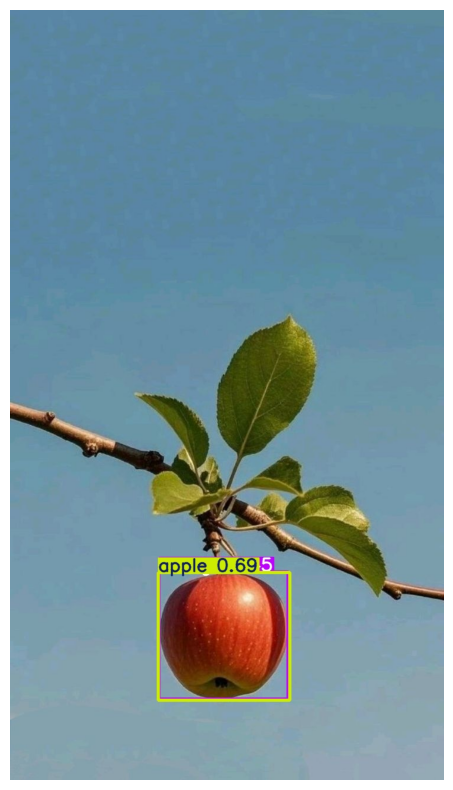

In [10]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

path_predict = project + '/predict/' + name_img

img = Image.open(os.path.join(project, path_predict))
image = mpimg.imread(path_predict)

plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

# **Treinamento de um modelo**

* **Definir o diretório**

In [5]:
# Caminho do diretório escolhido
path = "/content/drive/MyDrive/Faculdade/Minicurso_YOLO/Treinamento_Modelo_Teste"

* **Selecionar o modelo e realizar o treinamento**

Observação

*   Necessário um dataset com as labels e imagens organizadas corretamente - Explicação no GitHub


*   Configure o arquivo data.yaml na mesma pasta do diretório





In [16]:
# Load a model
model = YOLO("yolo11n.pt")  # load pre trained model


results = model.train(
    data=os.path.join(path, "data.yaml"),    # Nosso arquivo de configuração
    epochs=20,        # Ciclo de treinamento (100 é bom para o nosso caso)
    imgsz=640,           # Tamanho das imagens
    batch=16,            # Quantas imagens por vez (pode ser ajustado conforme necessário)
    patience=10         # Para se o modelo parar de evoluir
)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Faculdade/Minicurso_YOLO/Treinamento_Modelo_Teste/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2

* **Gravar os resultados do treinamentos**

In [17]:
import shutil
import os

source = '/content/runs'
destination = '/content/drive/MyDrive/Faculdade/Minicurso_YOLO/Treinamento_Modelo_Teste'

# Copiar o conteúdo de cada subdiretório e arquivo
for item in os.listdir(source):
    s = os.path.join(source, item)
    d = os.path.join(destination, item)
    if os.path.isdir(s):
        shutil.copytree(s, d, dirs_exist_ok=True)  # Requer Python 3.8 ou superior
    else:
        shutil.copy2(s, d)

* **Carregar o modelo treinado**

In [22]:
model = YOLO('/content/drive/MyDrive/Faculdade/Minicurso_YOLO/Treinamento_Modelo_Teste/detect/train-2/weights/best.pt')

In [30]:
# Imagem

name_img = 'laranja_2.jpg'


In [31]:
# CAMINHO DA IMAGEM PARA REALIZAR A PREDIÇÃO

image_path = project + name_img


results = model.predict(
    source=image_path,
    save=True,
    project=project,          # Define a pasta base no Drive
    exist_ok=True             # Só cria a pasta "predict" se ela não existir
)



image 1/1 /content/drive/MyDrive/Faculdade/Minicurso_YOLO_2/Images/laranja_2.jpg: 640x480 2 laranjas, 11.6ms
Speed: 2.2ms preprocess, 11.6ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/drive/MyDrive/Faculdade/Minicurso_YOLO_2/Images/predict


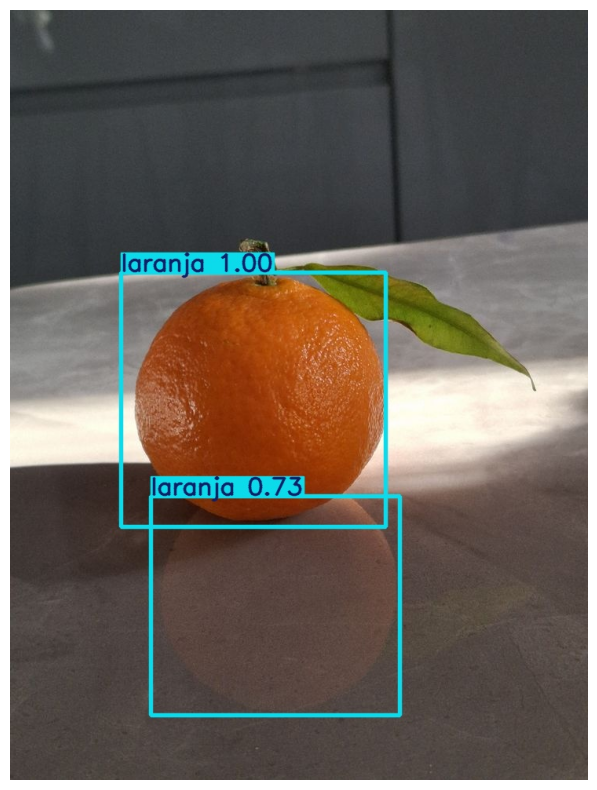

In [32]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

path_predict = project + '/predict/' + name_img

img = Image.open(os.path.join(project, path_predict))
image = mpimg.imread(path_predict)

plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis('off')
plt.show()